# Step 02: Forecast Demand
**Project:** Dynamic Agent Staffing Optimization (Google) · DADS 5250 Module 7 Hackathon

**Goal:** estimate eligible sign-ups for every country and month of 2026, using 2024 and 2025.

**Input:** `data/clean/monthly_eligible_demand.csv` (from Step 01)

**Output** (in the `data/clean/` folder):
| File | What it holds |
|---|---|
| `forecast_2026.csv` | Per country and month of 2026: forecast eligible sign-ups and the country's average budget |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

IN_FILE = "../data/clean/monthly_eligible_demand.csv"
OUT_FILE = "../data/clean/forecast_2026.csv"

## 1. Read the monthly data

In [2]:
monthly = pd.read_csv(IN_FILE)

# One row per country and month, one column per year
signups = monthly.pivot(index=["Country", "Month"], columns="Year", values="Eligible_Signups")
signups = signups.reset_index().rename_axis(columns=None)
print("Rows:", len(signups), "(expected 22 countries x 12 months = 264)")
signups.head()

Rows: 264 (expected 22 countries x 12 months = 264)


,Country,Month,2024,2025
0,Argentina,1,53,90
1,Argentina,2,66,76
2,Argentina,3,69,59
3,Argentina,4,71,79
4,Argentina,5,67,65


## 2. Choose the method
**Idea:** the forecast answers two simple questions.
1. **How big is the country in a year?** Country level = average yearly total of 2024 and 2025.
2. **How is the year split across months?** Month share = each month's share of the yearly total in 2024 and in 2025, averaged over the two years, using all countries together.

**Forecast = country level x month share**

**Example (Argentina, January 2026):** level = (911 + 892) / 2 = 901.5, January share = (6.9% in 2024 + 8.8% in 2025) / 2 = about 7.85%, so the forecast is 901.5 x 7.85% = about 70.8 sign-ups.

**Why this method:**
- **Same pattern everywhere:** all countries rise and fall in the same months (for example, October to December are the busiest), so one shared pattern is enough.
- **Stable for small countries:** a small country's own monthly numbers jump a lot (Argentina in January: 53 in 2024, 90 in 2025). The shared pattern smooths this out.
- **No trend needed:** yearly totals barely changed (about -1.5%), so averaging the two years is fair.
- **Lowest error:** in the 2025 test (Section 3) it beat the other simple methods.

In [3]:
def forecast(df, years):
    """Country yearly level x shared monthly pattern, averaged over the given years."""
    level = df.groupby("Country")[years].sum().mean(axis=1)
    share = (df.groupby("Month")[years].sum() / df[years].sum()).mean(axis=1)
    return df["Country"].map(level) * df["Month"].map(share)

## 3. Test the method on 2025
Each method is built from 2024 only and then compared with the real 2025 numbers.
- **MAPE:** average error per country and month (every country counts the same).
- **WAPE:** total error divided by total sign-ups (big countries count more). This is the main number, because staffing follows volume.

In [4]:
actual = signups[2025]
methods = {
    "Flat (same every month)": signups.groupby("Country")[2024].transform("mean"),
    "Same month last year": signups[2024],
    "Country level x shared pattern": forecast(signups, [2024]),
}

def errors(pred):
    err = (pred - actual).abs()
    return pd.Series({"MAPE": (err / actual).mean(), "WAPE": err.sum() / actual.sum()})

backtest = pd.DataFrame({name: errors(pred) for name, pred in methods.items()}).T
backtest.style.format("{:.1%}")

,MAPE,WAPE
Flat (same every month),19.0%,17.3%
Same month last year,15.1%,12.8%
Country level x shared pattern,14.1%,12.2%


## 4. Forecast 2026

In [5]:
fc = signups[["Country", "Month"]].copy()
fc["Forecast_Eligible_Signups"] = forecast(signups, [2024, 2025]).round(1)

# Budget is flat across months, so one weighted average per country
budget = (monthly.assign(Total=monthly["Eligible_Signups"] * monthly["Avg_Budget"])
                 .groupby("Country")[["Total", "Eligible_Signups"]].sum())
fc["Avg_Budget"] = fc["Country"].map(budget["Total"] / budget["Eligible_Signups"]).round(2)

# The 2026 total should equal the average of the 2024 and 2025 totals
expected = signups[[2024, 2025]].sum().mean()
assert len(fc) == 264
assert np.isclose(fc["Forecast_Eligible_Signups"].sum(), expected, rtol=1e-3)
print(f"2026 total: {fc['Forecast_Eligible_Signups'].sum():,.0f} | average of 2024 and 2025: {expected:,.0f}")
fc.head()

2026 total: 106,167 | average of 2024 and 2025: 106,167


,Country,Month,Forecast_Eligible_Signups,Avg_Budget
0,Argentina,1,70.8,11131.83
1,Argentina,2,68.2,11131.83
2,Argentina,3,69.1,11131.83
3,Argentina,4,68.7,11131.83
4,Argentina,5,68.3,11131.83


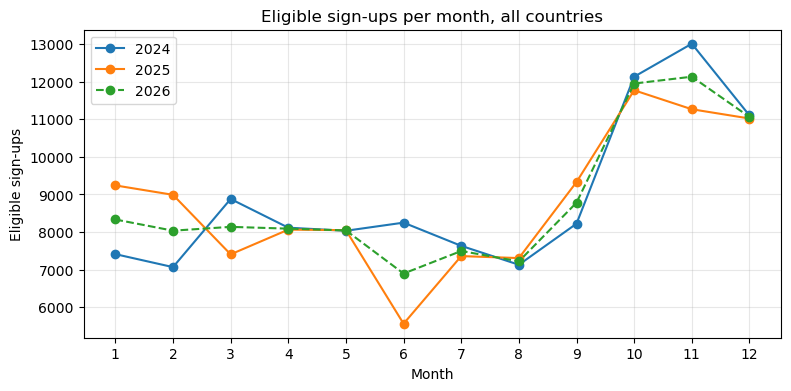

In [6]:
total = signups.groupby("Month")[[2024, 2025]].sum()
total[2026] = fc.groupby("Month")["Forecast_Eligible_Signups"].sum()
total.plot(marker="o", style=["-", "-", "--"], figsize=(9, 4), title="Eligible sign-ups per month, all countries")
plt.xlabel("Month")
plt.ylabel("Eligible sign-ups")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.show()

## 5. Save the forecast

In [7]:
fc.to_csv(OUT_FILE, index=False)
print("Saved", OUT_FILE, "|", len(fc), "rows")

Saved ../data/clean/forecast_2026.csv | 264 rows


## Decisions (for the report)
- **Method:** country yearly level x shared monthly pattern, both averaged over 2024 and 2025. In the 2025 test it had the lowest error (WAPE 12.2%, vs 12.8% for "same month last year" and 17.3% for a flat forecast).
- **No trend:** total eligible sign-ups changed by only about -1.5% from 2024 to 2025, so no growth rate is added.
- **No complex models:** 24 months of data is too short for models like ARIMA or Prophet.
- **Budget:** one weighted average per country (total budget / sign-ups), because the average budget hardly changes by month.